# Prediksi Harga Mobil Bekas

UAS Pengenalan Pola 

**Tujuan:** memprediksi `price_usd` (harga mobil bekas) dari data mobil seperti tahun, mesin, merek, dll.

**Metrik:** MAE, RMSE, dan R2. Model harus lebih bagus dari baseline (prediksi rata-rata harga).


## 1. Import library

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

## 2. Baca data dan cek data

In [4]:
df = pd.read_csv('used_car_prediction.csv')

In [5]:
df.head()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,price_usd,brand,transmission,color,service_history,accidents_reported,insurance_valid
0,2001,8.17,4000,Petrol,4,8587.64,Chevrolet,Manual,White,NaN,0,No
1,2014,17.59,1500,Petrol,4,5943.50,Honda,Manual,Black,NaN,0,Yes
2,2023,18.09,2500,Diesel,5,9273.58,BMW,Automatic,Black,Full,1,Yes
3,2009,11.28,800,Petrol,1,6836.24,Hyundai,Manual,Blue,Full,0,Yes
4,2005,12.23,1000,Petrol,2,4625.79,Nissan,Automatic,Red,Full,0,Yes


In [6]:
df.shape

(10000, 12)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           10000 non-null  int64  
 1   mileage_kmpl        10000 non-null  float64
 2   engine_cc           10000 non-null  int64  
 3   fuel_type           10000 non-null  str    
 4   owner_count         10000 non-null  int64  
 5   price_usd           10000 non-null  float64
 6   brand               10000 non-null  str    
 7   transmission        10000 non-null  str    
 8   color               10000 non-null  str    
 9   service_history     7962 non-null   str    
 10  accidents_reported  10000 non-null  int64  
 11  insurance_valid     10000 non-null  str    
dtypes: float64(2), int64(4), str(6)
memory usage: 937.6 KB


In [8]:
df.describe()

,make_year,mileage_kmpl,engine_cc,owner_count,price_usd,accidents_reported
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2009.206900,17.960753,2287.130000,3.003500,7179.754532,0.492200
std,8.373858,5.025486,1291.276927,1.418904,2795.270940,0.694109
min,1995.000000,5.000000,800.000000,1.000000,1000.000000,0.000000
25%,2002.000000,14.540000,1200.000000,2.000000,5176.547500,0.000000
50%,2009.000000,17.970000,1800.000000,3.000000,6961.260000,0.000000
75%,2016.000000,21.352500,3000.000000,4.000000,8993.732500,1.000000
max,2023.000000,35.000000,5000.000000,5.000000,17647.630000,5.000000


## 3. Cleaning

In [9]:
# cek missing value
df.isnull().sum()

make_year                0
mileage_kmpl             0
engine_cc                0
fuel_type                0
owner_count              0
price_usd                0
brand                    0
transmission             0
color                    0
service_history       2038
accidents_reported       0
insurance_valid          0
dtype: int64

In [10]:
# cek duplikat
df.duplicated().sum()

np.int64(0)

Missing value cuma ada di service history, tidak di hapus karena jumlahnya lumayan banyak, jadi di isi unknown 

In [11]:
df['service_history'] = df['service_history'].fillna('Unknown')
df.isnull().sum().sum()

np.int64(0)

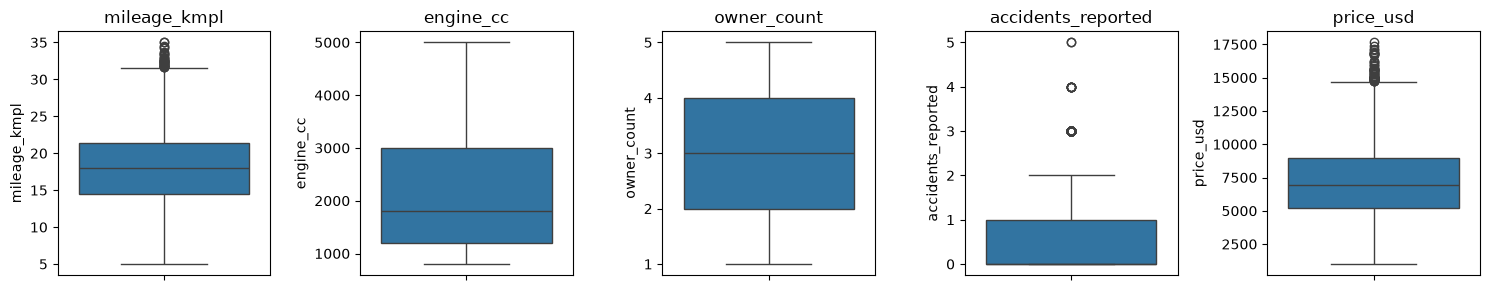

In [12]:
# cek outlier pakai boxplot
kolom_num = ['mileage_kmpl', 'engine_cc', 'owner_count', 'accidents_reported', 'price_usd']

plt.figure(figsize=(15, 3))
for i, col in enumerate(kolom_num):
    plt.subplot(1, 5, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [13]:
# cek nilai yang tidak masuk akal
print('harga <= 0         :', (df['price_usd'] <= 0).sum())
print('tahun > 2026       :', (df['make_year'] > 2026).sum())
print('owner_count < 1    :', (df['owner_count'] < 1).sum())
print('accidents < 0      :', (df['accidents_reported'] < 0).sum())

harga <= 0         : 0
tahun > 2026       : 0
owner_count < 1    : 0
accidents < 0      : 0


In [14]:
# cek fuel_type vs engine_cc (mobil listrik harusnya tidak punya cc)
df.groupby('fuel_type')[['engine_cc', 'mileage_kmpl']].describe().T

fuel_type                Diesel     Electric       Petrol
engine_cc    count  4058.000000   974.000000  4968.000000
             mean   2305.446033  2261.704312  2277.153784
             std    1301.226137  1268.400669  1287.621836
             min     800.000000   800.000000   800.000000
             25%    1200.000000  1200.000000  1200.000000
             50%    2000.000000  1800.000000  1800.000000
             75%    3000.000000  3000.000000  3000.000000
             max    5000.000000  5000.000000  5000.000000
mileage_kmpl count  4058.000000   974.000000  4968.000000
             mean     17.974256    18.053583    17.931524
             std       4.945536     5.024415     5.090799
             min       5.000000     5.000000     5.000000
             25%      14.460000    14.855000    14.550000
             50%      17.970000    18.135000    17.940000
             75%      21.397500    21.327500    21.342500
             max      34.990000    33.440000    35.000000

Dataset ini merupakan dataset sintetis. Apabila nilai engine_cc pada mobil listrik diubah menjadi 0 atau NaN, hal ini bisa mengganggu variasi data atau membuat model belajar aturan buatan. Oleh karena itu, data dibiarkan apa adanya dan masalah ini kami anggao sebagai keterbatasan data.

Kesimpulan cleaning: outlier tidak dihapus karena nilainya masih masuk akal (bukan salah input). Kalau di tabel terakhir mobil `Electric` ternyata punya `engine_cc`, itu masalah dari datanya, dicatat saja di keterbatasan.

## 4. EDA

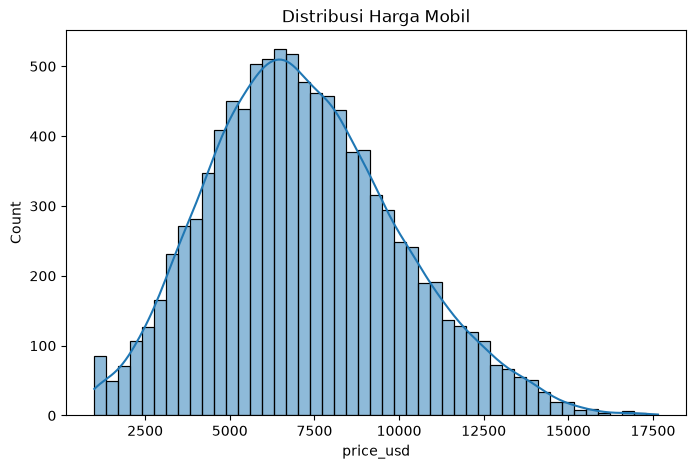

skewness harga: 0.35590379484454826


In [15]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='price_usd', kde=True)
plt.title('Distribusi Harga Mobil')
plt.show()

print('skewness harga:', df['price_usd'].skew())

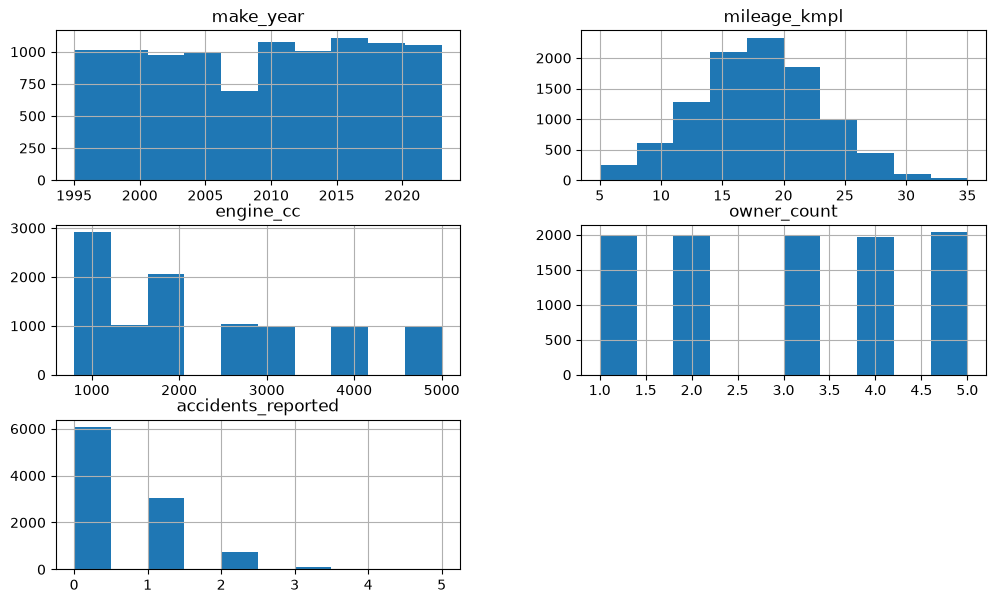

In [16]:
df[['make_year', 'mileage_kmpl', 'engine_cc', 'owner_count', 'accidents_reported']].hist(figsize=(12, 7))
plt.show()

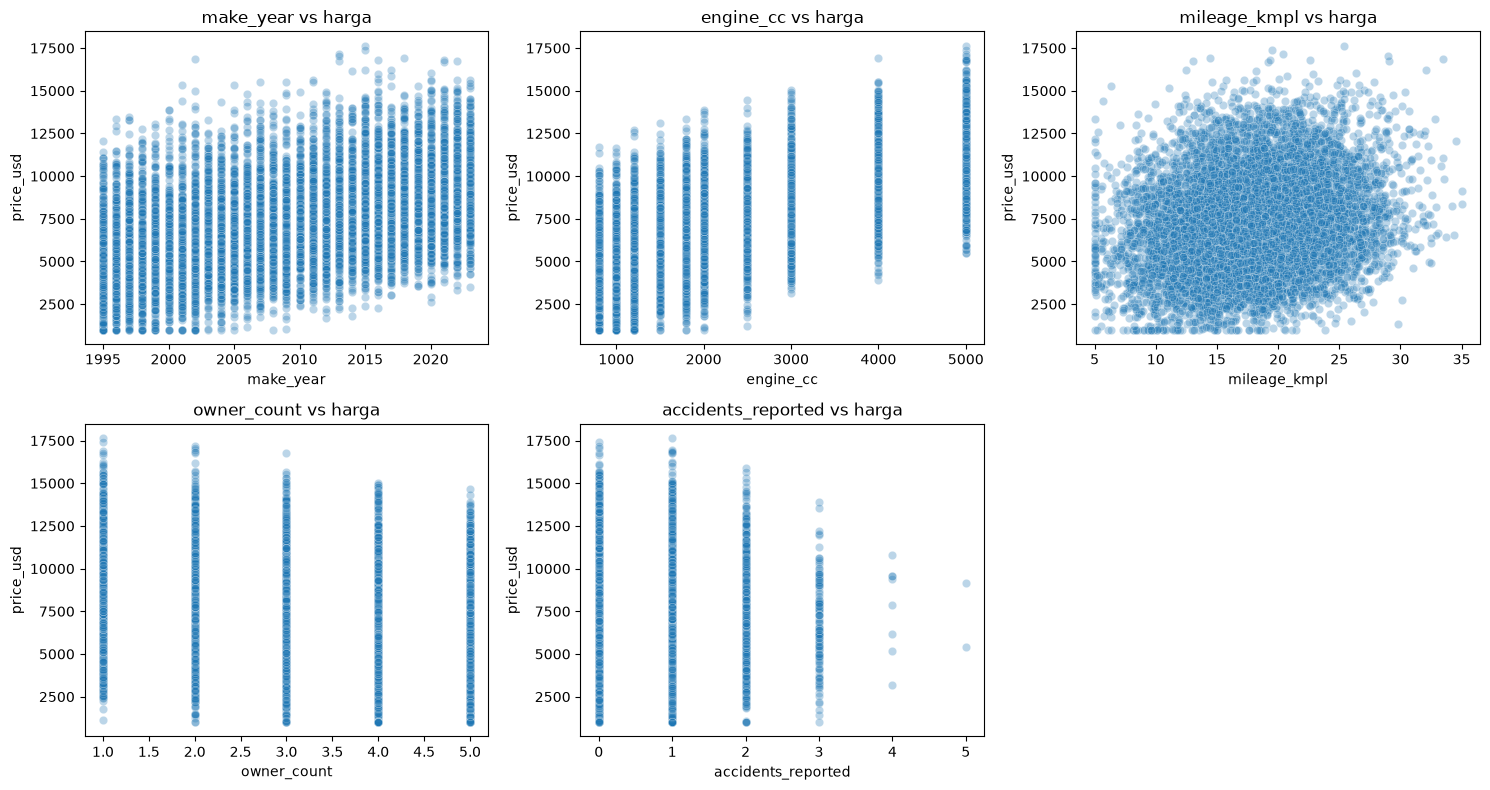

In [17]:
# fitur numerik vs harga
plt.figure(figsize=(15, 8))
for i, col in enumerate(['make_year', 'engine_cc', 'mileage_kmpl', 'owner_count', 'accidents_reported']):
    plt.subplot(2, 3, i + 1)
    sns.scatterplot(data=df, x=col, y='price_usd', alpha=0.3)
    plt.title(col + ' vs harga')
plt.tight_layout()
plt.show()

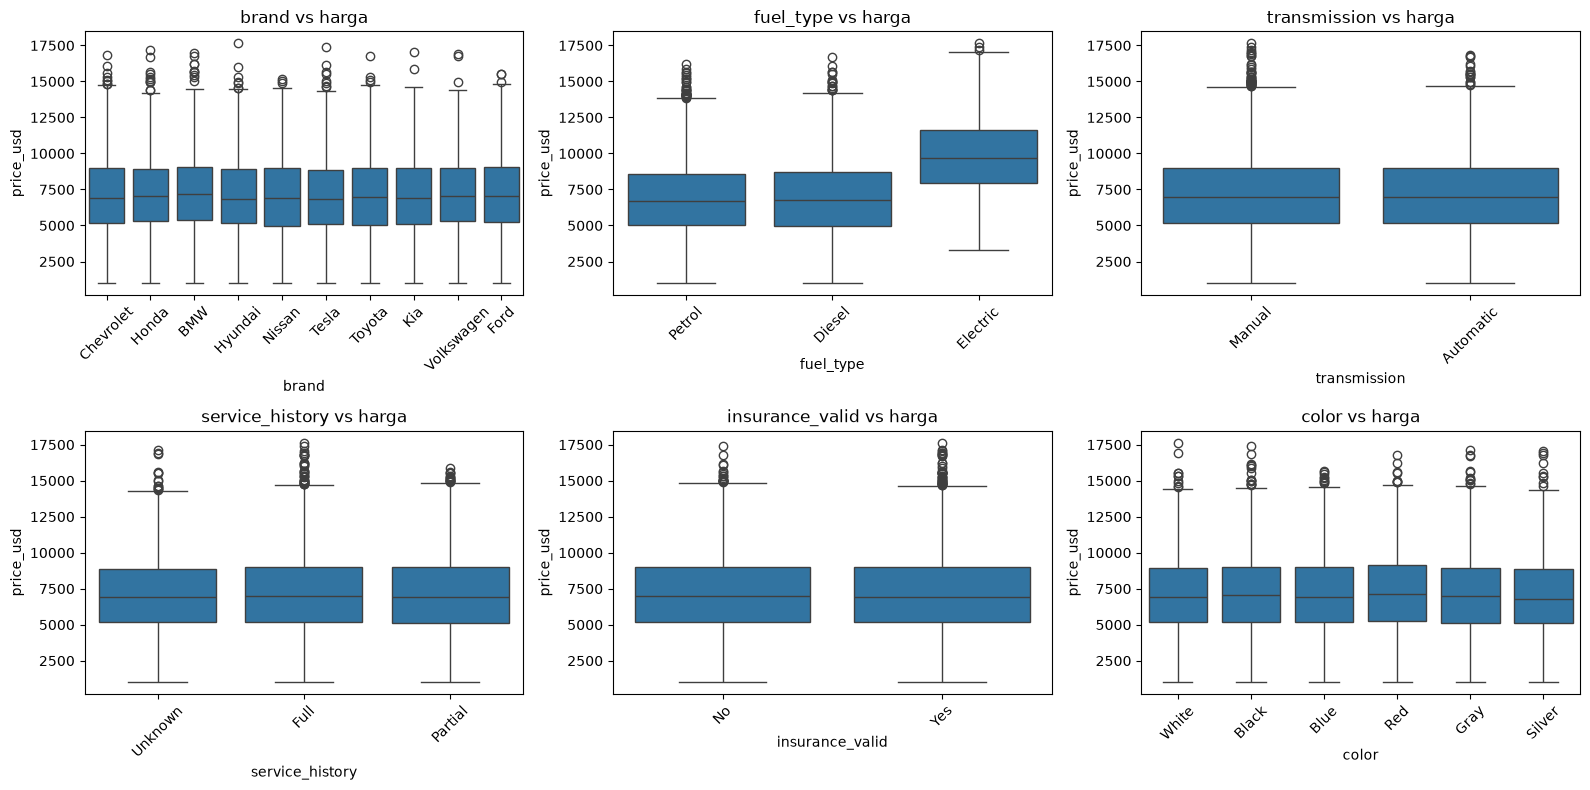

In [18]:
# fitur kategorikal vs harga
kolom_kat = ['brand', 'fuel_type', 'transmission', 'service_history', 'insurance_valid', 'color']

plt.figure(figsize=(16, 8))
for i, col in enumerate(kolom_kat):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(data=df, x=col, y='price_usd')
    plt.xticks(rotation=45)
    plt.title(col + ' vs harga')
plt.tight_layout()
plt.show()

In [19]:
df.groupby('color')['price_usd'].agg(['count', 'mean', 'median']).sort_values('median', ascending=False)

,count,mean,median
color,,,
Red,1678,7287.139678,7133.540
Black,1702,7216.539318,7027.635
Gray,1705,7190.391296,6971.680
White,1651,7147.743137,6915.310
Blue,1634,7197.815367,6898.645
Silver,1630,7033.989957,6803.635


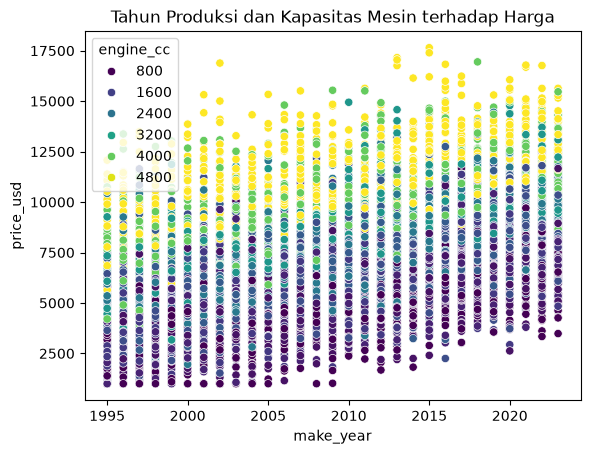

In [20]:
# apakah mobil baru dan mesin besar lebih mahal?
sns.scatterplot(data=df, x='make_year', y='price_usd', hue='engine_cc', palette='viridis')
plt.title('Tahun Produksi dan Kapasitas Mesin terhadap Harga')
plt.show()

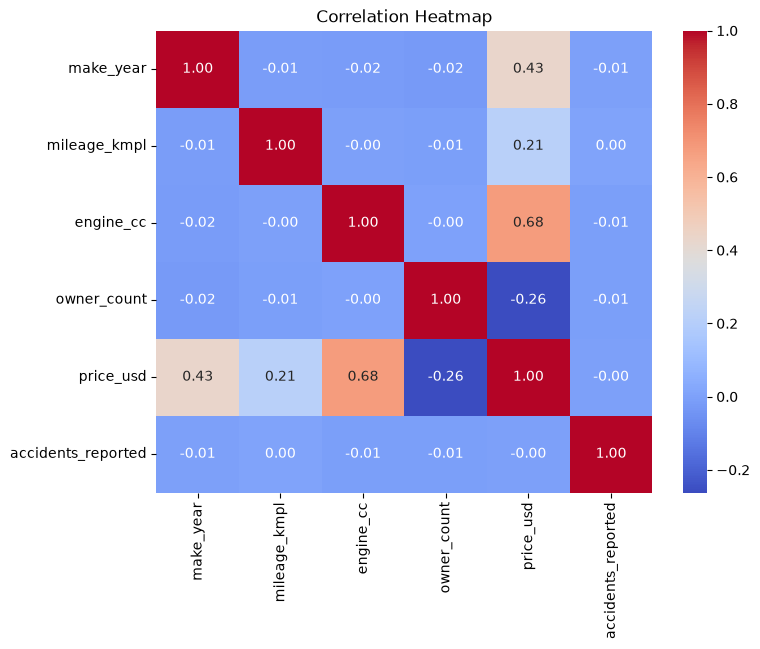

In [21]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()


- Makin lama tahun pembuatan, harga makin turun, jadi nanti dibuat fitur umur mobil.
- Merek, jenis bahan bakar, transmisi, dan riwayat servis kelihatan beda harganya antar kategori.
- Warna selisihnya kecil, tapi tetap dipakai dulu. Nanti dilihat penting atau tidak di feature importance.
- Korelasi cuma mengukur hubungan linear dan hanya untuk kolom angka.

## 5. Feature engineering
buat kolom `car_age` (umur mobil) dari `make_year`, lalu `make_year` dibuang karena informasinya sama.

In [22]:
df['car_age'] = 2026 - df['make_year']
df = df.drop(columns=['make_year'])
df.head()

,mileage_kmpl,engine_cc,fuel_type,owner_count,price_usd,brand,transmission,color,service_history,accidents_reported,insurance_valid,car_age
0,8.17,4000,Petrol,4,8587.64,Chevrolet,Manual,White,Unknown,0,No,25
1,17.59,1500,Petrol,4,5943.50,Honda,Manual,Black,Unknown,0,Yes,12
2,18.09,2500,Diesel,5,9273.58,BMW,Automatic,Black,Full,1,Yes,3
3,11.28,800,Petrol,1,6836.24,Hyundai,Manual,Blue,Full,0,Yes,17
4,12.23,1000,Petrol,2,4625.79,Nissan,Automatic,Red,Full,0,Yes,21


## 6. Split data

Data dibagi dulu sebelum encoding dan scaling supaya data test tidak ikut "dipelajari" (menghindari data leakage). Data test baru dipakai di akhir.

In [23]:
X = df.drop(columns=['price_usd'])
y = df['price_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)

(8000, 11)
(2000, 11)


## 7. Preprocessing

- kolom angka di-scale pakai StandardScaler
- kolom kategori di-encode pakai OneHotEncoder

Semua dimasukkan ke `Pipeline` bersama modelnya. Jadi saat cross validation, encoder dan scaler otomatis hanya fit di data train tiap fold (tidak bocor), dan nanti waktu deploy data mentah langsung bisa diprediksi.

In [24]:
kolom_angka = X_train.select_dtypes(include='number').columns.tolist()
kolom_kat = X_train.select_dtypes(exclude='number').columns.tolist()

print(kolom_angka)
print(kolom_kat)

['mileage_kmpl', 'engine_cc', 'owner_count', 'accidents_reported', 'car_age']
['fuel_type', 'brand', 'transmission', 'color', 'service_history', 'insurance_valid']


In [25]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), kolom_angka),
    ('cat', OneHotEncoder(handle_unknown='ignore'), kolom_kat)
])

# fungsi kecil supaya tidak nulis pipeline berulang
def buat_pipeline(model):
    return Pipeline([('prep', preprocessor), ('model', model)])

## 8. Bandingkan model (cross validation)

Kalau cuma satu kali split, hasilnya bisa kebetulan. Jadi dipakai cross validation 5 fold di data train. `Dummy` adalah baseline (selalu menebak rata-rata harga).

In [26]:
models = {
    'Dummy (baseline)': buat_pipeline(DummyRegressor()),
    'Linear Regression': buat_pipeline(LinearRegression()),
    'Decision Tree': buat_pipeline(DecisionTreeRegressor(random_state=42)),
    'Random Forest': buat_pipeline(RandomForestRegressor(n_estimators=100, random_state=42)),
    'Gradient Boosting': buat_pipeline(GradientBoostingRegressor(random_state=42))
}

In [27]:
results = []

for name, model in models.items():
    cv = cross_validate(model, X_train, y_train, cv=5, return_train_score=True,
                        scoring=['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error'])
    results.append({
        'Model': name,
        'R2 Train': cv['train_r2'].mean(),
        'R2 CV': cv['test_r2'].mean(),
        'MAE CV': -cv['test_neg_mean_absolute_error'].mean(),
        'RMSE CV': -cv['test_neg_root_mean_squared_error'].mean()
    })

df_cv = pd.DataFrame(results).sort_values('RMSE CV').reset_index(drop=True)
df_cv.round(4)

,Model,R2 Train,R2 CV,MAE CV,RMSE CV
0,Linear Regression,0.8710,0.8697,800.1764,1005.7194
1,Gradient Boosting,0.8798,0.8653,814.0317,1022.8559
2,Random Forest,0.9785,0.8470,868.8701,1089.6820
3,Decision Tree,1.0000,0.7016,1208.0369,1521.6661
4,Dummy (baseline),0.0000,-0.0014,2237.9680,2788.9552


Cara baca: bandingkan semua model dengan Dummy. Lalu lihat selisih R2 Train dan R2 CV, kalau jauh berarti overfitting. Decision Tree dan Random Forest yang belum di-tuning biasanya overfitting (R2 train hampir 1 tapi R2 CV jauh lebih kecil).

## 9. Hyperparameter tuning

Pakai GridSearchCV (cross validation 5 fold di data train) untuk model yang punya hyperparameter penting. Tujuannya mengurangi overfitting. Linear Regression tidak di-tuning karena tidak punya hyperparameter penting.

In [28]:
grids = {
    'Decision Tree': (buat_pipeline(DecisionTreeRegressor(random_state=42)), {
        'model__max_depth': [3, 5, 8, 12],
        'model__min_samples_leaf': [1, 10, 30]
    }),
    'Random Forest': (buat_pipeline(RandomForestRegressor(random_state=42)), {
        'model__n_estimators': [100, 200],
        'model__max_depth': [5, 10, None],
        'model__min_samples_leaf': [1, 5, 10]
    }),
    'Gradient Boosting': (buat_pipeline(GradientBoostingRegressor(random_state=42)), {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.05, 0.1],
        'model__max_depth': [2, 3, 4]
    })
}

In [29]:
tuned = {}

for name, (pipe, param_grid) in grids.items():
    print('tuning', name, '...')
    gs = GridSearchCV(pipe, param_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print('  parameter terbaik:', gs.best_params_)
    print('  RMSE CV:', round(-gs.best_score_, 2))

tuning Decision Tree ...
  parameter terbaik: {'model__max_depth': 12, 'model__min_samples_leaf': 10}
  RMSE CV: 1202.27
tuning Random Forest ...
  parameter terbaik: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
  RMSE CV: 1072.77
tuning Gradient Boosting ...
  parameter terbaik: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}
  RMSE CV: 1019.01


In [30]:
# bandingkan RMSE CV sebelum dan sesudah tuning
perbandingan = []
for name in tuned:
    sebelum = df_cv.loc[df_cv['Model'] == name, 'RMSE CV'].values[0]
    sesudah = -tuned[name].best_score_
    perbandingan.append({'Model': name, 'RMSE sebelum tuning': sebelum, 'RMSE sesudah tuning': sesudah})

pd.DataFrame(perbandingan).round(2)

,Model,RMSE sebelum tuning,RMSE sesudah tuning
0,Decision Tree,1521.67,1202.27
1,Random Forest,1089.68,1072.77
2,Gradient Boosting,1022.86,1019.01


## 10. Pilih model terbaik

Model dipilih dari hasil cross validation di data train (bukan dari data test). Yang RMSE CV-nya paling kecil yang dipilih.

In [31]:
# kumpulkan RMSE CV semua kandidat
kandidat = {}
kandidat['Linear Regression'] = df_cv.loc[df_cv['Model'] == 'Linear Regression', 'RMSE CV'].values[0]
for name in tuned:
    kandidat[name] = -tuned[name].best_score_

df_kandidat = pd.Series(kandidat).sort_values().to_frame('RMSE CV')
display(df_kandidat.round(2))

best_name = df_kandidat.index[0]
print('Model terpilih:', best_name)

,RMSE CV
Linear Regression,1005.72
Gradient Boosting,1019.01
Random Forest,1072.77
Decision Tree,1202.27


Model terpilih: Linear Regression


In [32]:
# latih model terpilih di seluruh data train
if best_name == 'Linear Regression':
    best_model = models['Linear Regression']
    best_model.fit(X_train, y_train)
else:
    best_model = tuned[best_name].best_estimator_

baseline = models['Dummy (baseline)']
baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['mileage_kmpl','engine_cc','fuel_type',...,'accidents_reported', 'insurance_valid','car_age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This su

## 11. Evaluasi di data test

Data test dipakai sekali saja, untuk model terpilih dan baseline.

In [33]:
def hitung_metrik(model, X_, y_):
    pred = model.predict(X_)
    return {
        'R2': r2_score(y_, pred),
        'MAE ($)': mean_absolute_error(y_, pred),
        'RMSE ($)': np.sqrt(mean_squared_error(y_, pred)),
        'MAPE (%)': np.mean(np.abs((y_ - pred) / y_)) * 100
    }

hasil = pd.DataFrame({
    best_name + ' (train)': hitung_metrik(best_model, X_train, y_train),
    best_name + ' (test)': hitung_metrik(best_model, X_test, y_test),
    'Baseline (test)': hitung_metrik(baseline, X_test, y_test)
}).T
hasil.round(4)

,R2,MAE ($),RMSE ($),MAPE (%)
Linear Regression (train),0.8709,797.1187,1001.7846,14.0255
Linear Regression (test),0.8765,791.0024,991.0165,14.0884
Baseline (test),-0.0009,2265.5244,2821.7655,45.8237


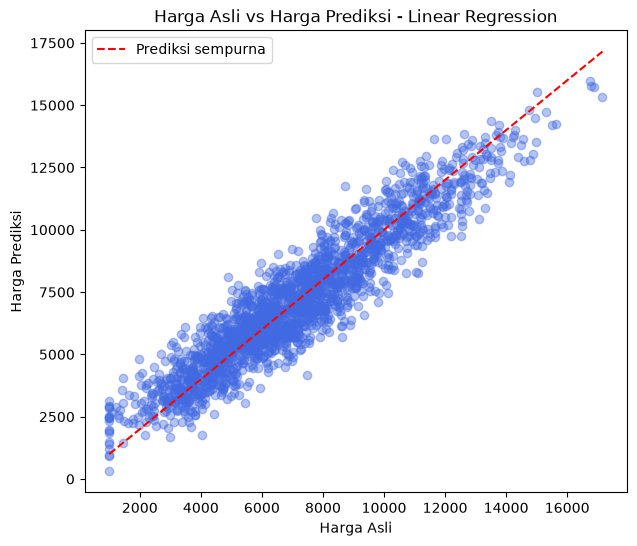

In [34]:
y_pred = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.4, color='royalblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Prediksi sempurna')
plt.xlabel('Harga Asli')
plt.ylabel('Harga Prediksi')
plt.title('Harga Asli vs Harga Prediksi - ' + best_name)
plt.legend()
plt.show()

### Analisis residual

Residual = harga asli - harga prediksi. Model yang bagus residualnya tersebar acak di sekitar 0, tidak membentuk pola, dan distribusinya mendekati normal.

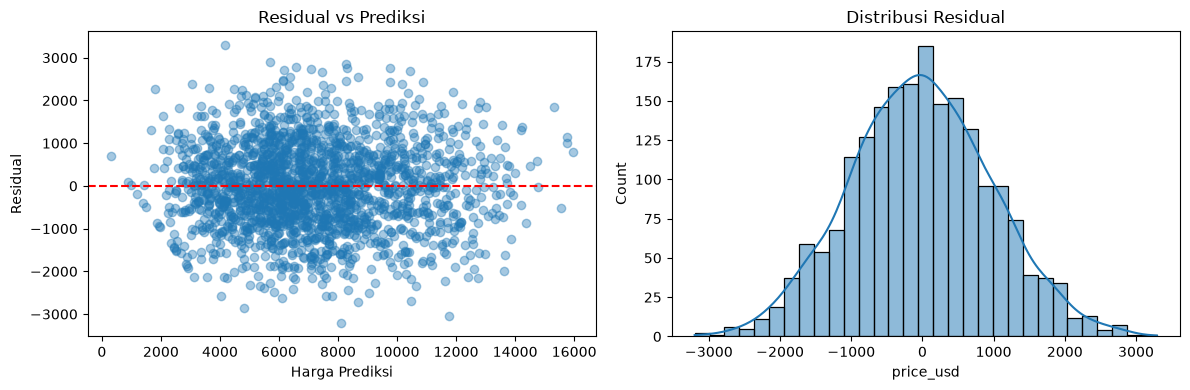

In [35]:
residual = y_test - y_pred

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.scatter(y_pred, residual, alpha=0.4)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Harga Prediksi')
plt.ylabel('Residual')
plt.title('Residual vs Prediksi')

plt.subplot(1, 2, 2)
sns.histplot(residual, kde=True)
plt.title('Distribusi Residual')

plt.tight_layout()
plt.show()

In [36]:
# error per kelompok umur mobil dan per merek (cari bagian yang prediksinya jelek)
cek = X_test.copy()
cek['error'] = np.abs(residual)
cek['kelompok_umur'] = pd.cut(cek['car_age'], bins=[0, 5, 10, 15, 20, 100])

print(cek.groupby('kelompok_umur', observed=True)['error'].mean().round(2))
print()
print(cek.groupby('brand')['error'].mean().round(2))

kelompok_umur
(0, 5]       855.99
(5, 10]      806.55
(10, 15]     772.10
(15, 20]     816.22
(20, 100]    762.56
Name: error, dtype: float64

brand
BMW           811.20
Chevrolet     773.82
Ford          743.39
Honda         760.49
Hyundai       800.36
Kia           825.68
Nissan        776.97
Tesla         752.21
Toyota        837.49
Volkswagen    845.41
Name: error, dtype: float64


## 12. Fitur apa yang paling berpengaruh

Pakai permutation importance: satu fitur diacak, lalu dilihat seberapa besar error naik. Cara ini bisa dipakai untuk model apa saja.

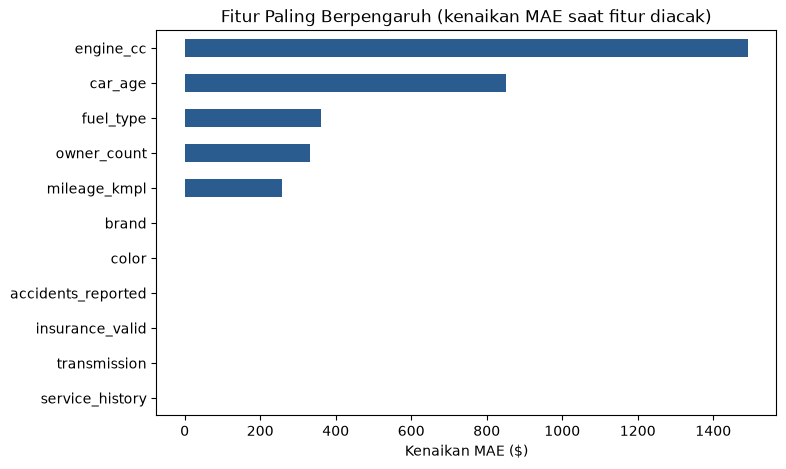

In [37]:
pi = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42,
                            scoring='neg_mean_absolute_error')

importance = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='#2b5c8f')
plt.gca().invert_yaxis()
plt.title('Fitur Paling Berpengaruh (kenaikan MAE saat fitur diacak)')
plt.xlabel('Kenaikan MAE ($)')
plt.show()

## 13. Contoh prediksi

In [38]:
sample_data = X_test.iloc[[0]]
actual_price = y_test.iloc[0]
predicted_price = best_model.predict(sample_data)[0]

print(f"Harga Asli     : ${actual_price:,.2f}")
print(f"Harga Prediksi : ${predicted_price:,.2f}")
print(f"Selisih        : ${abs(actual_price - predicted_price):,.2f}")

Harga Asli     : $12,772.12
Harga Prediksi : $12,124.39
Selisih        : $647.73


## 14. Kesimpulan


## 15. Simpan model dan deploy

Yang disimpan: model (pipeline lengkap) dan daftar pilihan input untuk form aplikasi. Aplikasinya pakai Streamlit.

In [39]:
import os
os.makedirs('deploy', exist_ok=True)

# simpan model
joblib.dump(best_model, 'deploy/model_mobil.pkl')

# simpan info untuk form aplikasi
info = {
    'model': best_name,
    'mae_test': float(hasil.loc[best_name + ' (test)', 'MAE ($)']),
    'r2_test': float(hasil.loc[best_name + ' (test)', 'R2']),
    'pilihan': {col: sorted(df[col].unique().tolist()) for col in kolom_kat},
    'min_max': {col: [float(df[col].min()), float(df[col].max())] for col in kolom_angka},
    'urutan_kolom': X_train.columns.tolist()
}
with open('deploy/info.json', 'w') as f:
    json.dump(info, f, indent=2)

os.listdir('deploy')

['info.json', 'model_mobil.pkl']

In [40]:
%%writefile deploy/app.py
import streamlit as st
import pandas as pd
import joblib
import json

model = joblib.load('model_mobil.pkl')
with open('info.json') as f:
    info = json.load(f)

pilihan = info['pilihan']
mm = info['min_max']

st.title('Prediksi Harga Mobil Bekas')
st.write('Model:', info['model'], '| R2 test:', round(info['r2_test'], 3), '| MAE test: $', round(info['mae_test']))

brand = st.selectbox('Merek', pilihan['brand'])
fuel_type = st.selectbox('Bahan bakar', pilihan['fuel_type'])
transmission = st.selectbox('Transmisi', pilihan['transmission'])
color = st.selectbox('Warna', pilihan['color'])
service_history = st.selectbox('Riwayat servis', pilihan['service_history'])
insurance_valid = st.selectbox('Asuransi masih berlaku', pilihan['insurance_valid'])

make_year = st.number_input('Tahun pembuatan', 1990, 2026, 2015)
engine_cc = st.number_input('Kapasitas mesin (cc)', int(mm['engine_cc'][0]), int(mm['engine_cc'][1]), 1500)
mileage_kmpl = st.number_input('Efisiensi bahan bakar (km/l)', float(mm['mileage_kmpl'][0]), float(mm['mileage_kmpl'][1]), 18.0)
owner_count = st.number_input('Jumlah pemilik sebelumnya', 1, 10, 2)
accidents_reported = st.number_input('Jumlah kecelakaan', 0, 10, 0)

if st.button('Prediksi'):
    data = pd.DataFrame([{
        'mileage_kmpl': mileage_kmpl,
        'engine_cc': engine_cc,
        'fuel_type': fuel_type,
        'owner_count': owner_count,
        'brand': brand,
        'transmission': transmission,
        'color': color,
        'service_history': service_history,
        'accidents_reported': accidents_reported,
        'insurance_valid': insurance_valid,
        'car_age': 2026 - make_year
    }])
    data = data[info['urutan_kolom']]
    harga = model.predict(data)[0]
    st.success(f'Perkiraan harga: ${harga:,.0f}')
    st.write(f"Kira-kira antara ${harga - info['mae_test']:,.0f} dan ${harga + info['mae_test']:,.0f}")

Writing deploy/app.py


In [41]:
# tes: model yang disimpan harus menghasilkan prediksi yang sama
model_load = joblib.load('deploy/model_mobil.pkl')

print(best_model.predict(X_test.head(3)))
print(model_load.predict(X_test.head(3)))

[12124.39047004  4688.22168024  7061.90011434]
[12124.39047004  4688.22168024  7061.90011434]


Cara menjalankan aplikasi (di terminal):

```
pip install streamlit
cd deploy
streamlit run app.py
```

Untuk online, upload folder `deploy` ke GitHub lalu deploy lewat Streamlit Community Cloud. Tambahkan file `requirements.txt` yang isinya `scikit-learn`, `pandas`, `joblib`, `streamlit`.